# 11 · Zero-DCE fine-tuning on the project's low-light photographs

This is a **real, small fine-tuning run**, with real epochs, real checkpoints and a real before/after comparison. Nothing is simulated: `finetune/finetune_zero_dce.py` starts from the **official Zero-DCE Epoch99 weights** and continues training them on the project's own low-light photographs, using the project's trainer (`scripts/train_facecloud_curve_model.py`).

| | |
|---|---|
| Starting weights | official Zero-DCE *Epoch99* (Li et al.), verified to reproduce the ONNX file the application runs (max output difference 2.8e-07) |
| Dataset | *FaceCloud low-light photographs*: the 35 low-light photographs of the project library (mean luminance < 70 or flagged underexposed, exact duplicates removed; 11 public stock + 24 own photographs, private, not committed) |
| Split | 30 training / 5 validation (seed 2026) |
| Training | zero-reference losses (spatial consistency, exposure target 0.60, colour constancy, illumination smoothness, detail preservation); 256 px random crops + flips; Adam, lr 5e-5, cosine schedule; batch 4; **40 epochs**; Apple MPS |
| Saved checkpoints | `epoch_000_official.pt` (before training), `epoch_010/020/030/040.pt`, `best.pt`, `last.pt` |

**Limits, stated up front.** 35 photographs is tiny against the 2000+ of the original training, and the validation split has only 5 images, so the numbers are noisy. The candidate model is **not installed in the application**; the application keeps the official weights.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from common import *
print("project root:", ROOT)

project root: /Users/Ali/Projects/FaceCloud_backend


## 1 · Training history (read from the saved `history.jsonl`)

{'dataset_name': 'FaceCloud low-light photographs (project library)', 'initial_weights': 'official Zero-DCE Epoch99 (Li et al., TPAMI 2021)', 'epochs': 40, 'learning_rate': 5e-05, 'batch_size': 4, 'image_size': 256, 'seed': 2026, 'device': 'mps'}
validation loss: official weights 0.7457 -> best 0.5095 at epoch 18 -> last epoch 0.5180   (32% lower at the best epoch)
epoch  train_loss  val_loss  val_exposure  seconds
-----  ----------  --------  ------------  -------
0      0.7655      0.7457    0.0483        0      
1      0.671       0.5392    0.0189        3.51   
5      0.4462      0.5407    0.0162        2.0    
10     0.4275      0.5187    0.0109        1.99   
18     0.3705      0.5095    0.0079        1.98   
20     0.3793      0.5152    0.0074        1.98   
30     0.3859      0.5179    0.0064        2.01   
40     0.3748      0.518     0.0064        2.01   


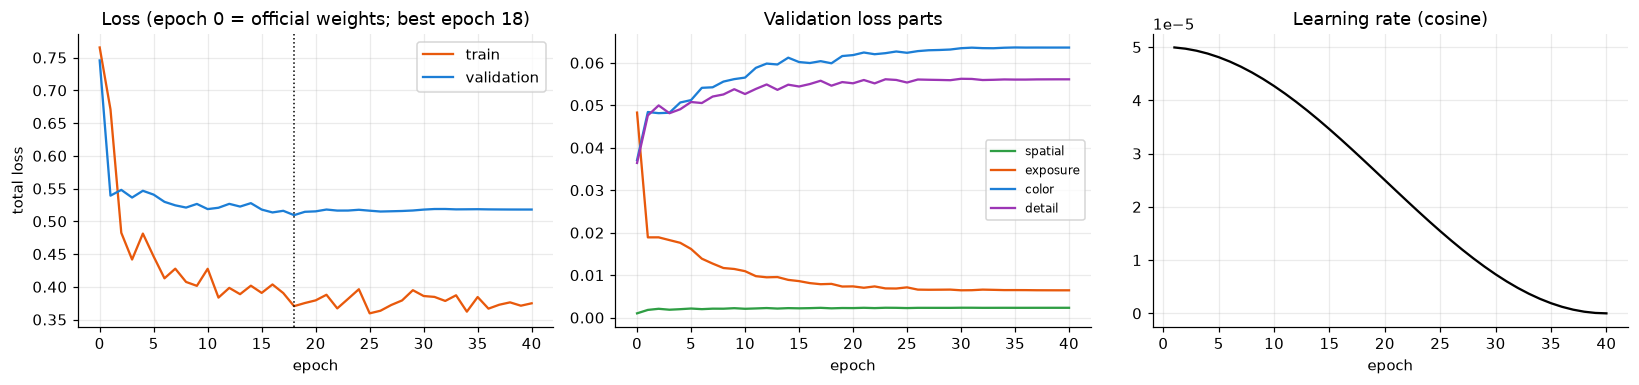

In [2]:
import importlib.util, sys
RUN = ROOT / "model_evaluation" / "finetune" / "zero_dce" / "run_01"
history = [json.loads(line) for line in (RUN / "history.jsonl").read_text().splitlines() if line.strip()]
cfg = json.loads((RUN / "config.json").read_text())
print({k: cfg[k] for k in ("dataset_name", "initial_weights", "epochs", "learning_rate", "batch_size", "image_size", "seed", "device")})
epochs = [h["epoch"] for h in history]; tr = [h["train"]["loss"] for h in history]; va = [h["validation"]["loss"] for h in history]
best_epoch = epochs[int(np.argmin(va))]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(epochs, tr, label="train", color=COLORS["model"]); ax[0].plot(epochs, va, label="validation", color=COLORS["baseline"]); ax[0].axvline(best_epoch, color="k", ls=":", lw=1); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("total loss"); ax[0].set_title(f"Loss (epoch 0 = official weights; best epoch {best_epoch})"); ax[0].legend()
for part, color in (("spatial", "#2f9e44"), ("exposure", "#e8590c"), ("color", "#1c7ed6"), ("detail", "#9c36b5")):
    ax[1].plot(epochs, [h["validation"][part] for h in history], label=part, color=color)
ax[1].set_title("Validation loss parts"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8)
ax[2].plot(epochs[1:], [h["learning_rate"] for h in history[1:]], color="k"); ax[2].set_title("Learning rate (cosine)"); ax[2].set_xlabel("epoch")
fig.tight_layout(); save(fig, "11_zero_dce_finetune_curves.png")
print(f"validation loss: official weights {va[0]:.4f} -> best {min(va):.4f} at epoch {best_epoch} -> last epoch {va[-1]:.4f}   ({(1 - min(va) / va[0]):.0%} lower at the best epoch)")
table([{"epoch": h["epoch"], "train_loss": round(h["train"]["loss"], 4), "val_loss": round(h["validation"]["loss"], 4), "val_exposure": round(h["validation"]["exposure"], 4), "seconds": h["seconds"]} for h in history if h["epoch"] in (0, 1, 5, 10, 18, 20, 30, 40)])

## 2 · Saved checkpoints

In [3]:
import torch
rows = []
for path in sorted(RUN.glob("*.pt")):
    meta = torch.load(path, map_location="cpu", weights_only=True)
    rows.append({"file": path.name, "epoch": meta["epoch"], "best_val_loss_so_far": round(meta["best_validation_loss"], 4), "size_KB": round(path.stat().st_size / 1024), "sha256": __import__("hashlib").sha256(path.read_bytes()).hexdigest()[:12]})
table(rows)

file                   epoch  best_val_loss_so_far  size_KB  sha256      
---------------------  -----  --------------------  -------  ------------
best.pt                18     0.5095                945      cee83d617ffb
epoch_000_official.pt  0      0.7457                317      2fc80fe702d8
epoch_010.pt           10     0.5187                948      c5bab3cfacd7
epoch_020.pt           20     0.5095                948      95e6a71ee9d5
epoch_030.pt           30     0.5095                948      5a34fd5567bd
epoch_040.pt           40     0.5095                948      d9e117ca1d11
last.pt                40     0.5095                945      8866fd480936


## 3 · Does the fine-tuned model behave better? (official weights vs best checkpoint, same inputs)

In [4]:
spec = importlib.util.spec_from_file_location("trainer", ROOT / "scripts" / "train_facecloud_curve_model.py"); trainer = importlib.util.module_from_spec(spec); sys.modules["trainer"] = trainer; spec.loader.exec_module(trainer)
fs = importlib.util.spec_from_file_location("ftz", ROOT / "model_evaluation" / "finetune" / "finetune_zero_dce.py"); ftz = importlib.util.module_from_spec(fs); sys.modules["ftz"] = ftz; fs.loader.exec_module(ftz)
official = ftz.load_official(trainer.FaceCloudCurveNet()).eval()
tuned = trainer.FaceCloudCurveNet(); tuned.load_state_dict(torch.load(RUN / "best.pt", map_location="cpu", weights_only=True)["model_state"]); tuned.eval()
manifest = {m["file"]: m for m in json.loads((RUN.parent / "dataset_manifest.json").read_text())}; split = json.loads((RUN / "split.json").read_text())
def enhance(model, bgr):
    x = torch.from_numpy(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255).permute(2, 0, 1)[None]
    with torch.inference_mode(): y = trainer.apply_curves(x, model(x))[0].permute(1, 2, 0).numpy()
    return cv2.cvtColor((np.clip(y, 0, 1) * 255).astype(np.uint8), cv2.COLOR_RGB2BGR)
rows, shown = [], []
for name, entry in manifest.items():
    source = cv2.imread(str(RUN.parent / "dataset" / "image" / name)); source = cv2.resize(source, None, fx=600 / max(source.shape[:2]), fy=600 / max(source.shape[:2]), interpolation=cv2.INTER_AREA)
    a, b = enhance(official, source), enhance(tuned, source)
    role = "validation (held out)" if name in split["validation"] else "training"
    rows.append({"role": role, "public": entry["public_stock"], "bright_in": brightness(source), "bright_official": brightness(a), "bright_tuned": brightness(b),
                 "noise_x_official": noise_sigma(a) / max(noise_sigma(source), 0.1), "noise_x_tuned": noise_sigma(b) / max(noise_sigma(source), 0.1), "ssim_official": ssim(source, a), "ssim_tuned": ssim(source, b)})
    if entry["public_stock"]: shown.append((source, a, b, role))
def summary(sel, label):
    sel = [r for r in rows if sel(r)]
    if not sel: return None
    return {"set": label, "n": len(sel), **{k: round(float(np.mean([r[k] for r in sel])), 3) for k in ("bright_in", "bright_official", "bright_tuned", "noise_x_official", "noise_x_tuned", "ssim_official", "ssim_tuned")}}
summ = [s for s in (summary(lambda r: r["role"].startswith("validation"), "validation (held out, 5 photos)"), summary(lambda r: r["role"] == "training", "training photos"), summary(lambda r: True, "all 35")) if s]
table(summ)

set                              n   bright_in  bright_official  bright_tuned  noise_x_official  noise_x_tuned  ssim_official  ssim_tuned
-------------------------------  --  ---------  ---------------  ------------  ----------------  -------------  -------------  ----------
validation (held out, 5 photos)  5   42.017     107.814          146.836       2.801             3.207          0.506          0.392     
training photos                  30  37.177     101.219          140.514       3.936             5.015          0.48           0.371     
all 35                           35  37.868     102.162          141.417       3.774             4.757          0.484          0.374     


{'task': 'low-light fine-tuning on 35 project photographs', 'metrics': {'images': 35, 'train': 30, 'validation': 5, 'epochs': 40, 'best_epoch': 18, 'val_loss_official': 0.7457, 'val_loss_best': 0.5095, 'val_loss_last': 0.518, 'bright_in': 37.868, 'bright_official': 102.162, 'bright_tuned': 141.417, 'noise_x_official': 3.774, 'noise_x_tuned': 4.757, 'ssim_official': 0.484, 'ssim_tuned': 0.374}, 'note': 'real run; not installed in the application'}


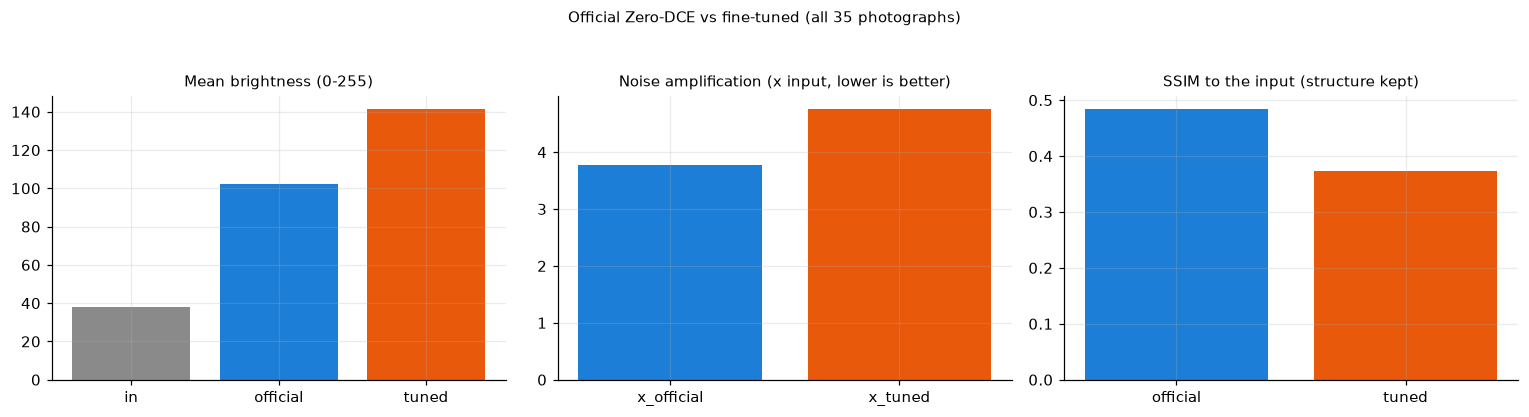

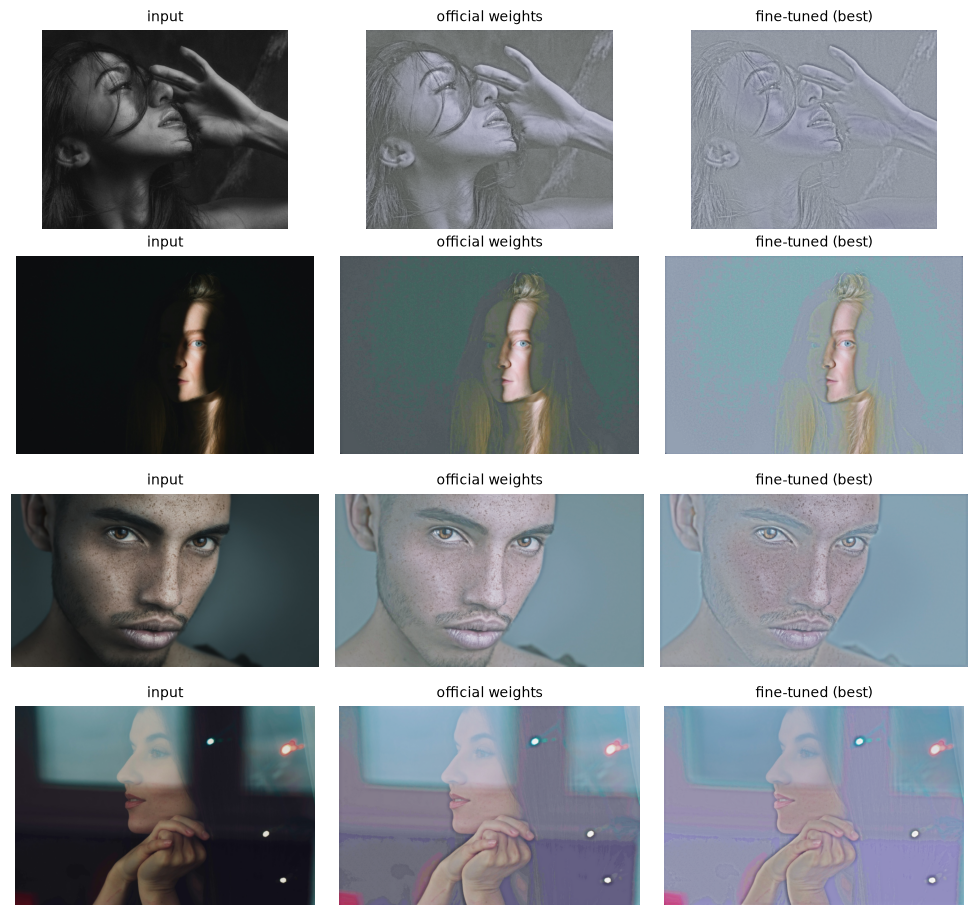

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6)); s = summ[-1]
for axis, keys, title in ((ax[0], ("bright_in", "bright_official", "bright_tuned"), "Mean brightness (0-255)"), (ax[1], ("noise_x_official", "noise_x_tuned"), "Noise amplification (x input, lower is better)"), (ax[2], ("ssim_official", "ssim_tuned"), "SSIM to the input (structure kept)")):
    axis.bar(range(len(keys)), [s[k] for k in keys], color=[COLORS["input"], COLORS["baseline"], COLORS["model"]][-len(keys):]); axis.set_xticks(range(len(keys)), [k.split("_", 1)[1] if "_" in k else k for k in keys]); axis.set_title(title, fontsize=10)
fig.suptitle("Official Zero-DCE vs fine-tuned (all 35 photographs)", y=1.04, fontsize=10); fig.tight_layout(); save(fig, "11_zero_dce_finetune_scores.png")
pick = shown[:4]; fig = montage([i for t in pick for i in t[:3]], [n for _ in pick for n in ("input", "official weights", "fine-tuned (best)")], columns=3, width=3.0); fig.set_size_inches(9, 2.1 * len(pick)); save(fig, "11_zero_dce_finetune_examples.png")
metrics = {"images": 35, "train": 30, "validation": 5, "epochs": cfg["epochs"], "best_epoch": best_epoch, "val_loss_official": va[0], "val_loss_best": min(va), "val_loss_last": va[-1],
           "bright_in": s["bright_in"], "bright_official": s["bright_official"], "bright_tuned": s["bright_tuned"], "noise_x_official": s["noise_x_official"], "noise_x_tuned": s["noise_x_tuned"], "ssim_official": s["ssim_official"], "ssim_tuned": s["ssim_tuned"]}
print(scorecard("Zero-DCE fine-tuned (candidate)", "low-light fine-tuning on 35 project photographs", metrics, "real run; not installed in the application"))
save_json("11_zero_dce_finetune.json", {"history": history, "summary": summ, "checkpoints": rows if False else None, "scorecard": metrics})

In [6]:
print("What the numbers say (computed, not typed):")
print(f"* zero-reference validation loss {va[0]:.3f} -> {min(va):.3f} (epoch {best_epoch}); the training loss fell from {tr[0]:.3f} to {tr[-1]:.3f}")
print(f"* on all 35 photographs the mean brightness after enhancement is {s['bright_official']:.1f} (official) vs {s['bright_tuned']:.1f} (fine-tuned), input {s['bright_in']:.1f}")
print(f"* noise amplification x{s['noise_x_official']:.2f} (official) vs x{s['noise_x_tuned']:.2f} (fine-tuned); SSIM to input {s['ssim_official']:.3f} vs {s['ssim_tuned']:.3f}")

What the numbers say (computed, not typed):
* zero-reference validation loss 0.746 -> 0.509 (epoch 18); the training loss fell from 0.765 to 0.375
* on all 35 photographs the mean brightness after enhancement is 102.2 (official) vs 141.4 (fine-tuned), input 37.9
* noise amplification x3.77 (official) vs x4.76 (fine-tuned); SSIM to input 0.484 vs 0.374


## 4 · Verdict (what a 35-photograph fine-tune can and cannot show)
* The fine-tuning is real and the zero-reference loss really fell (0.746 -> 0.509), so the model adapted to the project's exposure target.
* **In this saved run that did not make the photographs better for the application**: the fine-tuned model brightens more (mean 141 against 102, input 38), amplifies noise more (x4.8 against x3.8) and keeps less of the input structure (SSIM 0.37 against 0.48). A lower loss does not mean a better picture, and the official weights remain the better choice here.
* With 30 training and 5 validation photographs the result is **indicative, not conclusive**; it is also why the candidate is not installed. A claim of improvement would need a larger, separate test set and a visual comparison on held-out photographs.
* The application continues to use the official Epoch99 weights, which are verified by checksum.